# 🏦 Bank Müştəri Churn Proqnozlaşdırılması (Random Forest)
**Məqsəd:** Müştərinin bankı tərk etmə ehtimalını (`churned`) proqnozlaşdırmaq - Binary Classification.

**Pipeline:** Aqreqasiya (müştəri səviyyəsi) → Preprocessing → Random Forest → Qiymətləndirmə → Feature Importance

In [6]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, roc_auc_score, roc_curve, confusion_matrix

In [7]:
DATA_DIR = Path("/workspaces/Bank_Analysis/data/bank_data")

## 1. Data Ingestion & Feature Engineering (müştəri səviyyəsində aqreqasiya)
- **Demoqrafik məlumat:** `customers.csv` (hər müştəri 1 sətir, hədəf: `churned`).
- **Tranzaksiya davranışı:** `silver_transactions.csv` (Silverdə məzənnə `rate` və bayram `is_holiday` artıq birləşdirilib).
- Məzənnə `1 AZN = rate USD/EUR` formatındadır, ona görə AZN ekvivalenti = `amount / rate`.

In [8]:
# Tranzaksiyaları oxuyuruq və bütün məbləğləri AZN-ə çeviririk
tx = pd.read_csv(DATA_DIR / "silver_transactions.csv", low_memory=False)
tx["rate"] = tx["rate"].fillna(tx.groupby("currency")["rate"].transform("median"))
tx["rate"] = np.where(tx["currency"].str.lower() == "azn", 1.0, tx["rate"])
tx["amount_azn"] = tx["amount"] / tx["rate"]

In [9]:
# Hər müştəri üzrə xülasə (cəm, orta, say) çıxarırıq
tx_agg = tx.groupby("customer_id").agg(
    total_trans_count=("transaction_id", "count"),
    total_trans_amount=("amount_azn", "sum"),
    avg_trans_amount=("amount_azn", "mean"),
    holiday_trans_ratio=("is_holiday", "mean")
).reset_index()

In [10]:
# Müştəri profil cədvəlini oxuyub tranzaksiya xülasəsi ilə birləşdiririk
customers = pd.read_csv(DATA_DIR / "customers.csv")
customers["customer_id"] = customers["customer_id"].str.lower()
df = customers.drop(columns=["branch"], errors="ignore").merge(tx_agg, on="customer_id", how="left")

In [11]:
# Tranzaksiyası olmayan müştərilərin boş yerlərinə 0 yazırıq
trans_cols = ["total_trans_count", "total_trans_amount", "avg_trans_amount", "holiday_trans_ratio"]
df[trans_cols] = df[trans_cols].fillna(0)

In [12]:
# Kreditlərin oxunması və aqreqasiyası
loans = pd.read_csv(DATA_DIR / "silver_loans.csv", low_memory=False)
loans["customer_id"] = loans["customer_id"].str.lower()

loans_agg = loans.groupby("customer_id").agg(
    total_loan_count=("loan_id", "count"),
    rejected_loan_count=("status", lambda x: (x.astype(str).str.lower() == "rədd edildi").sum())
).reset_index()

# İkinci cədvəli də df-ə merge edirik:
df = df.merge(loans_agg, on="customer_id", how="left")
df[["total_loan_count", "rejected_loan_count"]] = df[["total_loan_count", "rejected_loan_count"]].fillna(0)

# Yekun cədvəlin ölçüsü və Churn (itki) nisbəti
print(f"Cədvəl ölçüsü (Müştəri sayı, Sütun sayı): {df.shape}")
print(f"Bankı tərk edən müştəri nisbəti: {df['churned'].mean():.1%}")
df.head()

Cədvəl ölçüsü (Müştəri sayı, Sütun sayı): (5000, 18)
Bankı tərk edən müştəri nisbəti: 20.2%


,customer_id,age,gender,city,tenure_years,credit_score,balance,salary,products_count,has_card,is_active,churned,total_trans_count,total_trans_amount,avg_trans_amount,holiday_trans_ratio,total_loan_count,rejected_loan_count
0,c00001,39,Qadın,Bakı,2,654,3156.63,908.98,2,1,0,0,3.0,105.340000,35.113333,0.000000,0,0
1,c00002,47,Kişi,Sumqayıt,7,779,1327.10,807.53,2,1,1,0,17.0,2821.830000,165.990000,0.176471,2,2
2,c00003,18,Qadın,Gəncə,0,675,7973.01,1564.52,3,1,1,0,24.0,2401.054900,100.043954,0.083333,2,0
3,c00004,41,Kişi,Bakı,3,726,1338.89,1422.36,1,1,1,0,24.0,2241.884453,93.411852,0.208333,0,0
4,c00005,38,Kişi,Bakı,2,703,26360.17,2581.86,1,0,1,0,22.0,2150.131987,97.733272,0.136364,3,1


## 2. Data Preprocessing & Preparation
- Əskik dəyərlər: rəqəmsal → median, kateqorial → ən çox rast gələn (yalnız **train** üzərində öyrənilir → data leakage yoxdur).
- `gender`, `city` → One-Hot Encoding; rəqəmsal əlamətlər → `StandardScaler`.
- Stratified 80/20 split (`stratify=y`).

In [13]:
from sklearn.compose import make_column_transformer
from sklearn.pipeline import make_pipeline

# Sütunların təyini
CAT_COLS, TARGET = ["gender", "city"], "churned"
NUM_COLS = [c for c in df.columns if c not in CAT_COLS + [TARGET, "customer_id"]]

In [14]:
# Train və Test-ə bölünmə (X və y-i ayrı dəyişən etmədən birbaşa bölürük)
X_train, X_test, y_train, y_test = train_test_split(
    df.drop(columns=[TARGET, "customer_id"]), 
    df[TARGET], 
    test_size=0.2, 
    stratify=df[TARGET], 
    random_state=42
)

In [15]:
# Yığcam Preprocessor (make_ pipeline və make_column_transformer ilə)
preprocessor = make_column_transformer(
    (make_pipeline(SimpleImputer(strategy="median"), StandardScaler()), NUM_COLS),
    (make_pipeline(SimpleImputer(strategy="most_frequent"), OneHotEncoder(handle_unknown="ignore")), CAT_COLS)
)

print(f"Train: {X_train.shape} / Test: {X_test.shape}")
print(f"Churn payı - Train: {y_train.mean():.1%}, Test: {y_test.mean():.1%}")

Train: (4000, 16) / Test: (1000, 16)
Churn payı - Train: 20.2%, Test: 20.2%


## 3. Model Training (Random Forest)
`class_weight='balanced'` azlıq sinfinə (churn) daha çox çəki verir. Hiperparametrlər overfitting-i azaltmaq üçün mühafizəkar seçilib.

In [16]:
from sklearn.pipeline import make_pipeline

# Pipeline qurulur və öyrədilir
model = make_pipeline(
    preprocessor,
    RandomForestClassifier(
        n_estimators=300, max_depth=10, min_samples_leaf=5,
        class_weight="balanced", random_state=42, n_jobs=-1
    )
)
model.fit(X_train, y_train)

# Test datası üzrə proqnozlar alınır
y_proba = model.predict_proba(X_test)[:, 1]  
y_pred = model.predict(X_test)               # Qəti qərar (0 və ya 1)

## 4. Evaluation & Visualization

              precision    recall  f1-score   support

   Qalır (0)       0.90      0.79      0.84       798
   Gedir (1)       0.45      0.66      0.53       202

    accuracy                           0.77      1000
   macro avg       0.68      0.73      0.69      1000
weighted avg       0.81      0.77      0.78      1000

ROC-AUC: 0.8062


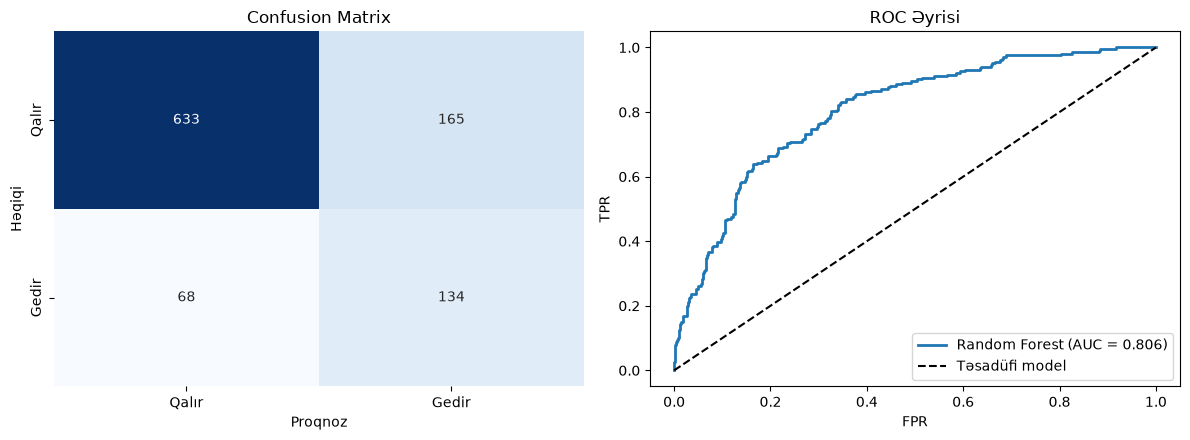

In [17]:
#  Model Evaluation (Optimallaşdırılmış yığcam versiya)
print(classification_report(y_test, y_pred, target_names=["Qalır (0)", "Gedir (1)"]))
auc = roc_auc_score(y_test, y_proba)
print(f"ROC-AUC: {auc:.4f}")

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

# 1) Confusion Matrix
sns.heatmap(confusion_matrix(y_test, y_pred), annot=True, fmt="d", cmap="Blues", cbar=False, ax=axes[0],
            xticklabels=["Qalır", "Gedir"], yticklabels=["Qalır", "Gedir"])
axes[0].set(title="Confusion Matrix", xlabel="Proqnoz", ylabel="Həqiqi")

# 2) ROC Əyrisi
fpr, tpr, _ = roc_curve(y_test, y_proba)
axes[1].plot(fpr, tpr, lw=2, label=f"Random Forest (AUC = {auc:.3f})")
axes[1].plot([0, 1], [0, 1], "k--", label="Təsadüfi model")
axes[1].set(title="ROC Əyrisi", xlabel="FPR", ylabel="TPR")
axes[1].legend(loc="lower right")

plt.tight_layout()
plt.show()

## 5. Feature Importance (Top 10)

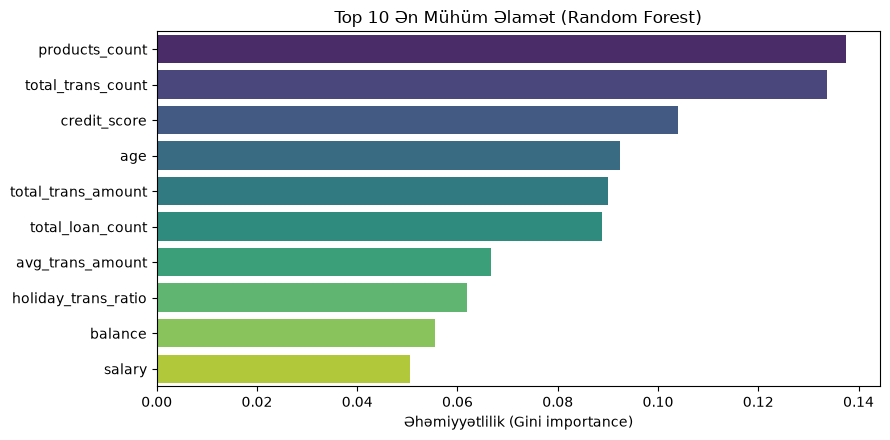

products_count         0.1374
total_trans_count      0.1337
credit_score           0.1039
age                    0.0924
total_trans_amount     0.0899
total_loan_count       0.0888
avg_trans_amount       0.0666
holiday_trans_ratio    0.0619
balance                0.0554
salary                 0.0506
dtype: float64

In [18]:
prep_step = model.steps[0][1]
rf_step = model.steps[1][1]

feat_names = [n.split("__", 1)[1] for n in prep_step.get_feature_names_out()]
importance = (pd.Series(rf_step.feature_importances_, index=feat_names)
              .sort_values(ascending=False).head(10))

plt.figure(figsize=(9, 4.5))
sns.barplot(x=importance.values, y=importance.index, hue=importance.index, palette="viridis", legend=False)
plt.title("Top 10 Ən Mühüm Əlamət (Random Forest)")
plt.xlabel("Əhəmiyyətlilik (Gini importance)"); plt.ylabel("")
plt.tight_layout(); plt.show()

display(importance.round(4))

## 6. Ehtimal Kalibrasiyası və Threshold = 0.35
`class_weight='balanced'` modelin ehtimallarını **şişirir** (orta ehtimal ≈ 0.35, real churn isə 0.20). Ona görə:
- **Qərar həddi (0.35)** modelin xam skorlarına tətbiq olunur — recall prioritetdir.
- **Kalibrasiya olunmuş ehtimal** (`CalibratedClassifierCV`) isə biznesə oxunaqlı "real churn ehtimalı" kimi təqdim olunur (gözlənilən itki hesabı, kampaniya ROI üçün).

⚠️ 0.35 həddi *kalibrasiya olunmuş* skalaya tətbiq edilsə, recall kəskin düşür (cədvələ bax) — iki skalanı qarışdırmayın.

,Recall (Gedənləri Tutma),Precision (Dəqiqlik),Riskli İşarələnən %
Hədd (Threshold),,,
0.20,0.975,0.254,0.777
0.25,0.931,0.278,0.676
0.30,0.906,0.298,0.614
0.35,0.871,0.334,0.527
0.40,0.842,0.370,0.460
0.50,0.663,0.448,0.299



=== YEKUN MODEL HESABATI (Biznes Həddi = 0.35) ===
              precision    recall  f1-score   support

   Qalır (0)       0.95      0.56      0.70       798
   Gedir (1)       0.33      0.87      0.48       202

    accuracy                           0.62      1000
   macro avg       0.64      0.72      0.59      1000
weighted avg       0.82      0.62      0.66      1000



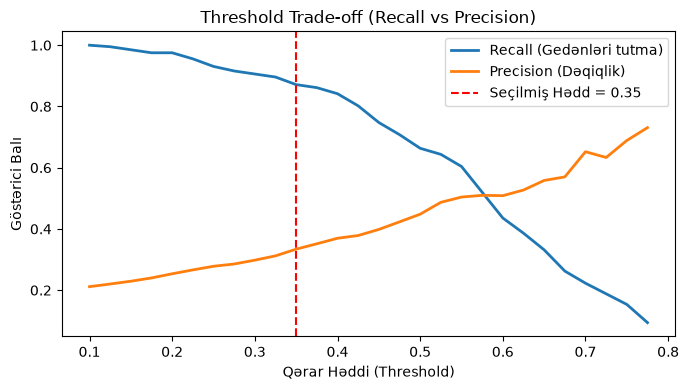

In [24]:
# 6. Biznes Qərar Həddinin Optimizasiyası (Thresholding = 0.35)
from sklearn.metrics import recall_score, precision_score, classification_report

THRESHOLD = 0.35

# A. Müxtəlif qərar hədləri üzrə Recall və Precision müqayisəsi
thresholds = [0.20, 0.25, 0.30, 0.35, 0.40, 0.50]
rows = []

for t in thresholds:
    y_pred_t = (y_proba >= t).astype(int)
    rows.append({
        "Hədd (Threshold)": t,
        "Recall (Gedənləri Tutma)": recall_score(y_test, y_pred_t),
        "Precision (Dəqiqlik)": precision_score(y_test, y_pred_t, zero_division=0),
        "Riskli İşarələnən %": (y_pred_t).mean()
    })

thresh_df = pd.DataFrame(rows).set_index("Hədd (Threshold)").round(3)
display(thresh_df)

# B. Seçilmiş hədd (0.35) üzrə Yekun Model Hesabatı
y_pred_final = (y_proba >= THRESHOLD).astype(int)
print(f"\n=== YEKUN MODEL HESABATI (Biznes Həddi = {THRESHOLD}) ===")
print(classification_report(y_test, y_pred_final, target_names=["Qalır (0)", "Gedir (1)"]))

# C. Precision-Recall Trade-off Qrafiki
grid = np.arange(0.1, 0.8, 0.025)
plt.figure(figsize=(7, 4))
plt.plot(grid, [recall_score(y_test, y_proba >= t) for t in grid], label="Recall (Gedənləri tutma)", lw=2)
plt.plot(grid, [precision_score(y_test, y_proba >= t, zero_division=0) for t in grid], label="Precision (Dəqiqlik)", lw=2)
plt.axvline(THRESHOLD, color="red", linestyle="--", label=f"Seçilmiş Hədd = {THRESHOLD}")
plt.title("Threshold Trade-off (Recall vs Precision)")
plt.xlabel("Qərar Həddi (Threshold)"); plt.ylabel("Göstərici Balı"); plt.legend()
plt.tight_layout(); plt.show()


[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: pip install --upgrade pip


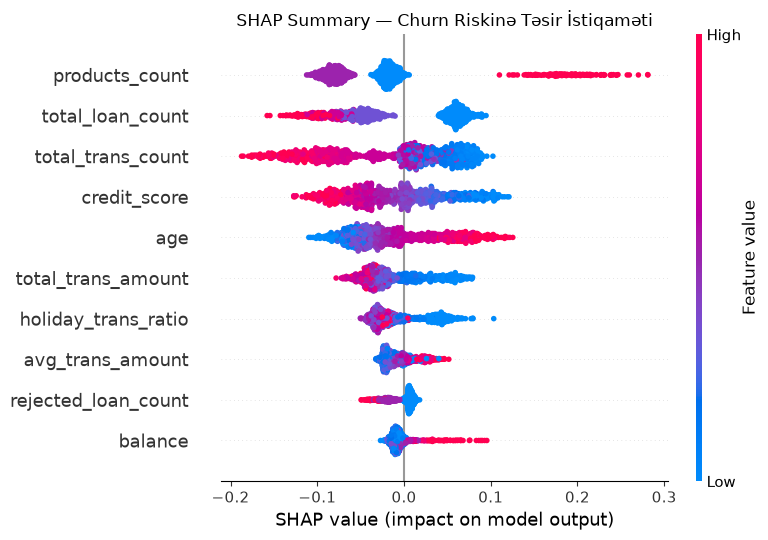

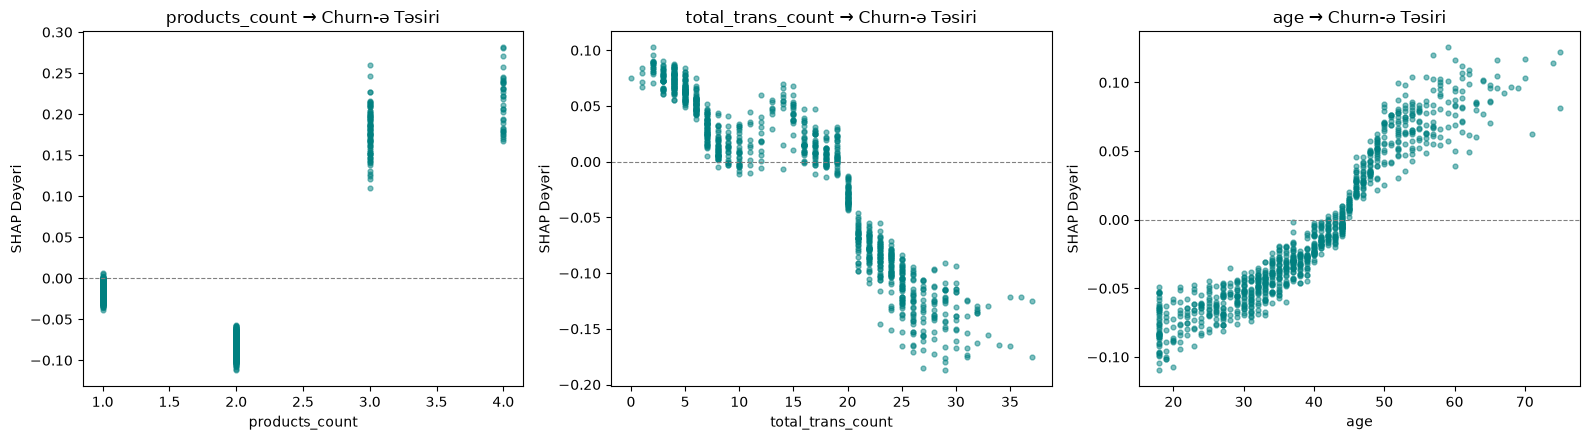

In [26]:
# 7. Model İzah Edilməsi (SHAP - Explainable AI)
!pip install shap -q
import shap
import pandas as pd
import matplotlib.pyplot as plt

# Addımların indekslə təhlükəsiz seçilməsi
prep_step = model.steps[0][1]
rf_step = model.steps[1][1]

# Sütun adları və datanın transform olunması
feat_names = [n.split("__", 1)[1] for n in prep_step.get_feature_names_out()]
X_t = prep_step.transform(X_test)
X_shap = pd.DataFrame(X_t.toarray() if hasattr(X_t, "toarray") else X_t, columns=feat_names)

# SHAP dəyərlərinin hesablanması
explainer = shap.TreeExplainer(rf_step)
sv = explainer.shap_values(X_shap)
sv = sv[1] if isinstance(sv, list) else (sv[:, :, 1] if sv.ndim == 3 else sv)

# 1) Qlobal Təsir (Beeswarm Summary Plot)
plt.figure(figsize=(9, 5))
shap.summary_plot(sv, X_shap, max_display=10, show=False)
plt.title("SHAP Summary — Churn Riskinə Təsir İstiqaməti", fontsize=12)
plt.tight_layout()
plt.show()

# 2) Qeyri-xətti Asılılıq Qrafikləri (Top-3 Əlamət)
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, feat in zip(axes, ["products_count", "total_trans_count", "age"]):
    if feat in X_test.columns:
        ax.scatter(X_test[feat].values, sv[:, list(feat_names).index(feat)], s=12, alpha=0.5, color="teal")
        ax.axhline(0, color="gray", linestyle="--", lw=0.8)
        ax.set(title=f"{feat} → Churn-ə Təsiri", xlabel=feat, ylabel="SHAP Dəyəri")

plt.tight_layout()
plt.show()

## 8. Seqmentlərin Vizuallaşdırılması
Seqmentləşdirmə **bütün müştərilər** üzərində aparılır. Overfitting olmasın deyiləm, hər müştərinin ehtimalı `cross_val_predict` ilə (onu görməmiş modeldən) alınır. Seqmentlər üst-üstə düşmür: müştəri sıra ilə ilk uyğun gələn seqmentə düşür.

,customers,churn_rate,churners,churner_share
segment,,,,
A: Kritik (risk + az tranzaksiya),1340,0.358,480,0.476
B: Çox məhsullu (3+),444,0.405,180,0.179
C: Qeyri-aktiv müştərilər,637,0.118,75,0.074
D: 55+ yaş qrupu,249,0.197,49,0.049
E: Digər risklər (Model),519,0.249,129,0.128
F: Aşağı risk,1811,0.052,95,0.094


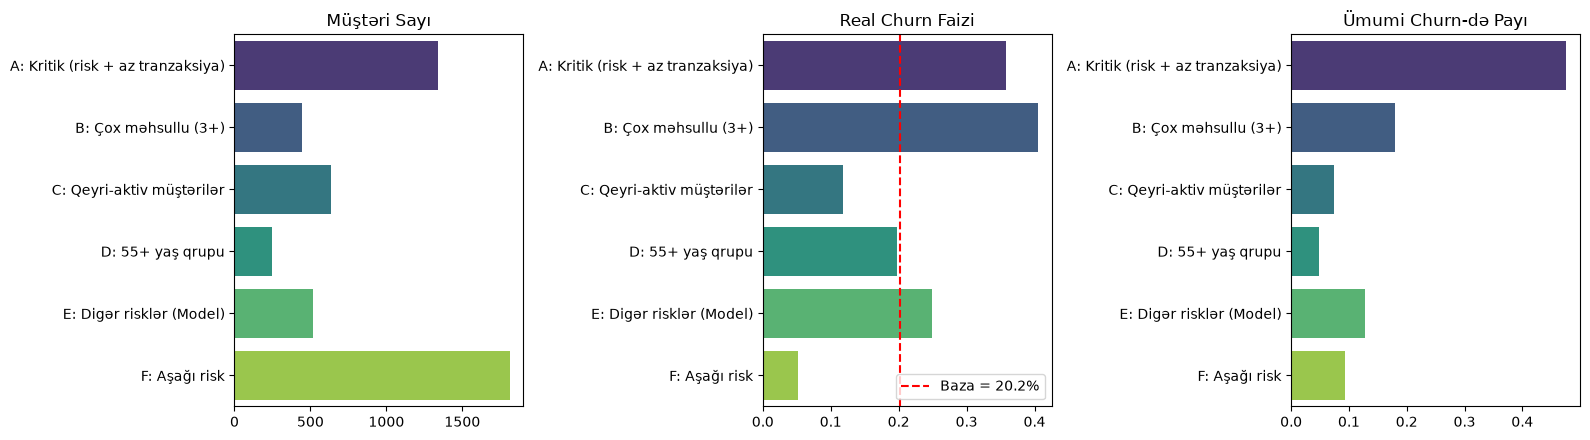

In [27]:
# 8. Biznes Seqmentasiyası və Risk Qrupları Analysis
from sklearn.model_selection import StratifiedKFold, cross_val_predict

# A. Bütöv data üzrə X və y təyini
X_full = df.drop(columns=["churned", "customer_id"], errors="ignore")
y_full = df["churned"]
THRESHOLD = 0.35

# B. 5-Fold Cross Validation ilə bütün müştərilərin risk ehtimalı
oof = cross_val_predict(model, X_full, y_full, cv=StratifiedKFold(5, shuffle=True, random_state=42), method="predict_proba", n_jobs=-1)[:, 1]

# C. Qruplaşdırma Məntiqi
seg = X_full.assign(churned=y_full, flagged=oof >= THRESHOLD)

SEGMENTS = [
    ("A: Kritik (risk + az tranzaksiya)", seg.flagged & (seg.total_trans_count <= 7)),
    ("B: Çox məhsullu (3+)",              seg.products_count >= 3),
    ("C: Qeyri-aktiv müştərilər",          seg.is_active == 0),
    ("D: 55+ yaş qrupu",                   seg.age >= 55),
    ("E: Digər risklər (Model)",          seg.flagged),
]

seg["segment"] = np.select([c for _, c in SEGMENTS], [n for n, _ in SEGMENTS], default="F: Aşağı risk")

# D. Xülasə cədvəli
summary = (seg.groupby("segment").agg(
    customers=("churned", "size"),
    churn_rate=("churned", "mean"),
    churners=("churned", "sum")
).assign(churner_share=lambda d: d.churners / d.churners.sum()).round(3))

display(summary)

# E. Vizuallaşdırma
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
panels = [("customers", "Müştəri Sayı", None), ("churn_rate", "Real Churn Faizi", y_full.mean()), ("churner_share", "Ümumi Churn-də Payı", None)]

for ax, (col, title, ref) in zip(axes, panels):
    sns.barplot(x=summary[col], y=summary.index, hue=summary.index, palette="viridis", legend=False, ax=ax)
    if ref: ax.axvline(ref, color="red", linestyle="--", label=f"Baza = {ref:.1%}"); ax.legend()
    ax.set(title=title, xlabel="", ylabel="")

plt.tight_layout()
plt.show()